# Supplementary Figure 4 — colocalisation by RNA-processing class

The corrected version of the `colocs` plot, which exists in two disagreeing
exploratory versions: `analysis/Figure_4.ipynb` cell 93 and
`analysis/PruebaF4.ipynb` cell 31.

Three corrections, all documented in `SFigure4_helpers`:

1. **No `TopCandidateSNP` filter.** PruebaF4 drops every row where hyprcoloc
   reported no top candidate SNP — 99,134 of 140,517 rows (71%). Those are
   tested loci that did not colocalise, so they are informative and are kept
   here. Dropping them lowers every `counter` and inflates every percentage.
2. **Fixed tick labels.** Both notebooks write `new_name == '...'` instead of
   `new_name = '...'` for `TRANSETHNICRA` and `ADHD`, so those two bars
   silently inherit the previous bar's label — in PruebaF4 the ADHD bar is
   labelled as a second *Multiple sclerosis*. All 65 labels are now unique.
3. **Consistent 'All traits' annotation.** That column was annotated with a
   hard-coded 1740 (colocalised loci) while every per-trait bar is annotated
   with its testable-loci count. It now carries the matching total.

In [1]:
import os
import pickle
import sys

import numpy as np
import pandas as pd
import matplotlib
from matplotlib import pyplot as plt

SFIG4_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/SFigure4'
ANALYSIS_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/analysis'

os.chdir(ANALYSIS_DIR)
if SFIG4_DIR not in sys.path:
    sys.path.append(SFIG4_DIR)

from SFigure4_helpers import run_all, MIN_REGIONS
import SFigure4_plot_helpers as PH

matplotlib.rcParams.update({
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
    'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans'],
})

data_dir = os.path.join(SFIG4_DIR, 'figure_data')

## Data

One pass over the hyprcoloc output; everything is pickled into `figure_data/`.

In [2]:
# Everything is cheap (two table reads and one pass over 140k rows), so the
# pipeline is run rather than reloaded. To reload instead:
#   def L(n):
#       with open(os.path.join(data_dir, f'{n}.pkl'), 'rb') as f:
#           return pickle.load(f)
#   filtering_trace, trait_df, colocs_panel = L('filtering_trace'), L('trait_df'), L('colocs_panel')
data = run_all(data_dir)

filtering_trace = data['filtering_trace']
trait_df = data['trait_df']
colocs_panel = data['colocs_panel']

[SFigure4] hyprcoloc results and lead-SNP windows ...


[SFigure4] isoform annotation ...


[SFigure4] per-trait RNA-processing classes ...


## Filtering trace

From `gwas_traits_for_coloc` in `code/rules/common.py` to the 65 traits in the
figure, with what each step drops — and the provenance of the 1740.

In [3]:
# Every filtering step from the GWAS trait pool that code/rules/common.py
# defines down to the traits and loci that reach the figure.
print(filtering_trace.to_string(index=False))
print()
print(f"distinct GWAS lead SNPs submitted                 : "
      f"{filtering_trace.attrs['lead_snps']}")
print(f"colocalized regions across the plotted traits     : "
      f"{filtering_trace.attrs['colocalized_regions']}")
print("   ^ the 1740 hard-coded over the 'All traits' bar in the exploratory"
      "\n     notebooks, and the number of events in the Figure 4 upset plot"
      "\n     (Figure4/figure_data/upset_data.pkl, which has exactly 1740 rows).")
print()
print(f"traits tested   : {colocs_panel['n_tested_traits']}  "
      f"(>= {MIN_REGIONS} tested regions; 3 of them colocalized nothing)")
print(f"traits plotted  : {colocs_panel['trait_selected_df'].shape[0]}  "
      f"(the 65 with at least one colocalized region get a bar)")
print(f"tested regions  : {colocs_panel['total_loci']}   "
      f"(denominator of the 'All traits' column, all 68 traits)")
print(f"colocalized     : {colocs_panel['total_coloc']}   "
      f"= {colocs_panel['total_percent']:.1f}%")

                                                       step  traits  GWAS_regions                                                                          dropped
            0. gwas_traits_for_coloc (code/rules/common.py)      85           NaN                                         every one has a leadSnps bed and windows
             1. lead-SNP windows submitted for those traits      85        9458.0                                        -67 windows from SLEVYSE, not in the pool
             2. window tested (hyprcoloc returned a result)      84        9057.0 -401 windows with nothing to colocalise against; -1 trait (parietal_lobe_volume)
                          3. trait has >= 10 tested regions      68        9016.0                                                                       -16 traits
4. trait has >= 1 colocalized region (percentage_coloc > 0)      65        8966.0        -3 traits (genetic_generalized_epilepsy, migraine, total_cerebral_volume)

distinct GWAS lead SN

## Supplementary Figure 4

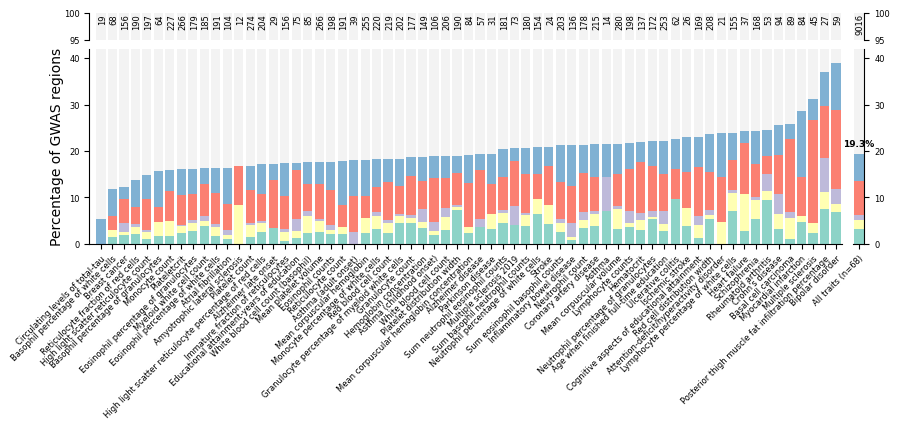

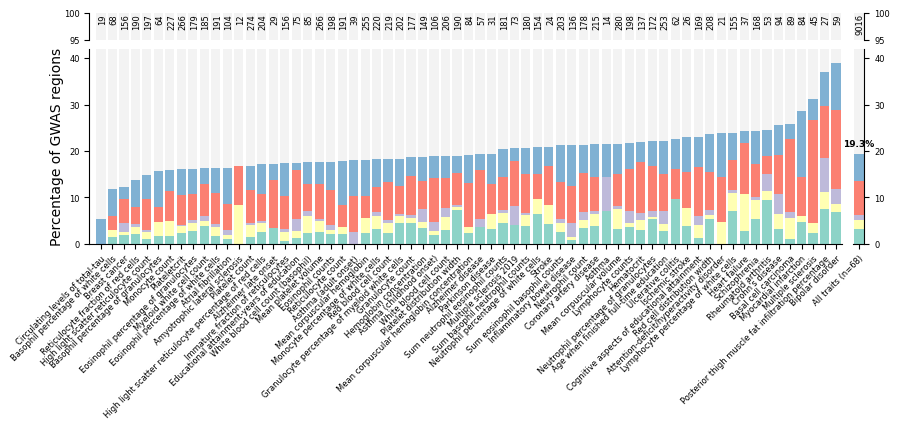

In [4]:
fig = PH.plot_colocs(colocs_panel)
for ext in ('pdf', 'png', 'svg'):
    kw = {'dpi': 500} if ext == 'png' else {}
    fig.savefig(os.path.join(SFIG4_DIR, f'SFigure4.{ext}'),
                bbox_inches='tight', **kw)
fig

## Colour key

Saved as its own figure (`SFigure4_legend.pdf` / `.png` / `.svg`) so it can be
placed beside the panel by hand. Each band is the gap between consecutive
cumulative sums of the stack, so a colour means a single RNA-processing class,
a combination of them, or no class at all.

   Intron retention (280)
   3' UTR (184)
   Cassette exon (90)
   Two or more classes (658)
   Colocalized, no class assigned (528)
   Tested, no colocalization (7,226)



saved SFigure4_legend.pdf / .png / .svg


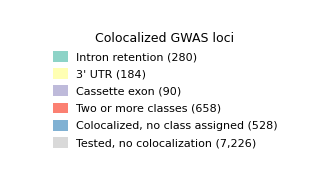

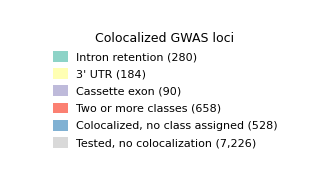

In [5]:
# The colour key, as a figure of its own so it can be placed beside the panel by
# hand. The bands are the gaps between consecutive cumulative sums of the stack,
# so each colour means a single class, a combination, or no class at all --
# legend_entries() documents the arithmetic.
for _lab, _col in PH.legend_entries(colocs_panel, counts=True):
    print(f'   {_lab}')

fig_legend = PH.plot_legend(colocs_panel, counts=True,
                            title='Colocalized GWAS loci')
for _ext in ('pdf', 'png', 'svg'):
    fig_legend.savefig(os.path.join(SFIG4_DIR, f'SFigure4_legend.{_ext}'),
                       dpi=400 if _ext == 'png' else None, bbox_inches='tight')
print('\nsaved SFigure4_legend.pdf / .png / .svg')
fig_legend

## Filtering funnel as a table

Traits and GWAS regions surviving each step, written to
`SFigure4_filtering_trace.md`.

In [6]:
# The filtering funnel as markdown, ready to paste into the supplement.
from IPython.display import Markdown, display

funnel_md = filtering_trace.rename(columns={
    'step': 'Step', 'traits': 'Traits', 'GWAS_regions': 'GWAS regions',
    'dropped': 'What drops here'}).to_markdown(index=False)
funnel_md = (f"**Traits and GWAS regions at every filtering step**\n\n{funnel_md}\n\n"
             f"Colocalized regions across the {colocs_panel['n_tested_traits']} tested "
             f"traits: **{filtering_trace.attrs['colocalized_regions']}** "
             f"({colocs_panel['total_percent']:.1f}% of "
             f"{colocs_panel['total_loci']}), which is also the number of events "
             f"in the Figure 4 upset plot.")

with open(os.path.join(SFIG4_DIR, 'SFigure4_filtering_trace.md'), 'w') as fh:
    fh.write(funnel_md + '\n')
display(Markdown(funnel_md))

**Traits and GWAS regions at every filtering step**

| Step                                                        |   Traits |   GWAS regions | What drops here                                                                  |
|:------------------------------------------------------------|---------:|---------------:|:---------------------------------------------------------------------------------|
| 0. gwas_traits_for_coloc (code/rules/common.py)             |       85 |            nan | every one has a leadSnps bed and windows                                         |
| 1. lead-SNP windows submitted for those traits              |       85 |           9458 | -67 windows from SLEVYSE, not in the pool                                        |
| 2. window tested (hyprcoloc returned a result)              |       84 |           9057 | -401 windows with nothing to colocalise against; -1 trait (parietal_lobe_volume) |
| 3. trait has >= 10 tested regions                           |       68 |           9016 | -16 traits                                                                       |
| 4. trait has >= 1 colocalized region (percentage_coloc > 0) |       65 |           8966 | -3 traits (genetic_generalized_epilepsy, migraine, total_cerebral_volume)        |

Colocalized regions across the 68 tested traits: **1740** (19.3% of 9016), which is also the number of events in the Figure 4 upset plot.

## Per-trait table

All 85 submitted traits, with the 68 that had enough tested regions flagged
`Tested`, and a pooled `Total` row. Written to `SFigure4_trait_table.tsv`
and `.md`.

In [7]:
# Per-trait table over all 85 submitted traits, with a pooled Total row.
# `tested` is tested_regions >= MIN_REGIONS, the rule that keeps 68 traits.
trait_table = data['trait_table']

trait_table.to_csv(os.path.join(SFIG4_DIR, 'SFigure4_trait_table.tsv'),
                   sep='\t', index=False)
table_md = trait_table.rename(columns={
    'trait': 'Trait', 'accession': 'Accession',
    'total_leadSnps': 'Total leadSNPs', 'tested_regions': 'Tested regions',
    'tested': 'Tested', 'colocs': 'Colocs',
    'percent_coloc': '% colocalized'}).to_markdown(index=False)
with open(os.path.join(SFIG4_DIR, 'SFigure4_trait_table.md'), 'w') as fh:
    fh.write(table_md + '\n')

print(f'{len(trait_table) - 1} traits + Total row  ->  '
      f'SFigure4_trait_table.tsv / .md')
display(Markdown(table_md))

85 traits + Total row  ->  SFigure4_trait_table.tsv / .md


| Trait                                                       | Accession                                                   |   Total leadSNPs |   Tested regions |   Tested |   Colocs |   % colocalized |
|:------------------------------------------------------------|:------------------------------------------------------------|-----------------:|-----------------:|---------:|---------:|----------------:|
| Mean corpuscular volume                                     | GCST004602                                                  |              292 |              280 |     True |       60 |            21.4 |
| Age when finished full-time education                       | age_when_finished_full-time_education                       |              307 |              253 |     True |       56 |            22.1 |
| Red cell distribution width                                 | GCST004621                                                  |              209 |              208 |     True |       49 |            23.6 |
| Mean platelet volume                                        | GCST004599                                                  |              268 |              266 |     True |       47 |            17.7 |
| Coronary artery disease                                     | coronary_artery_disease                                     |              221 |              215 |     True |       46 |            21.4 |
| Platelet count                                              | GCST004603                                                  |              285 |              274 |     True |       46 |            16.8 |
| Mean corpuscular hemoglobin                                 | GCST004630                                                  |              263 |              255 |     True |       46 |            18   |
| Plateletcrit                                                | GCST004607                                                  |              278 |              266 |     True |       43 |            16.2 |
| Sum eosinophil basophil counts                              | GCST004624                                                  |              208 |              203 |     True |       43 |            21.2 |
| Lymphocyte counts                                           | GCST004627                                                  |              204 |              198 |     True |       43 |            21.7 |
| Schizophrenia                                               | schizophrenia                                               |              202 |              168 |     True |       41 |            24.4 |
| Red blood cell count                                        | GCST004601                                                  |              225 |              219 |     True |       40 |            18.3 |
| Monocyte percentage of white cells                          | GCST004609                                                  |              232 |              220 |     True |       40 |            18.2 |
| Cognitive aspects of educational attainment                 | cognitive_aspects_of_educational_attainment                 |              198 |              169 |     True |       39 |            23.1 |
| White blood cell count                                      | GCST004610                                                  |              208 |              206 |     True |       39 |            18.9 |
| Neutrophil percentage of granulocytes                       | GCST004623                                                  |              177 |              172 |     True |       38 |            22.1 |
| Neutrophil count                                            | GCST004629                                                  |              181 |              178 |     True |       38 |            21.3 |
| Granulocyte percentage of myeloid white cells               | GCST004608                                                  |              212 |              202 |     True |       37 |            18.3 |
| Sum neutrophil eosinophil counts                            | GCST004613                                                  |              184 |              181 |     True |       37 |            20.4 |
| Sum basophil neutrophil counts                              | GCST004620                                                  |              184 |              180 |     True |       37 |            20.6 |
| Lymphocyte percentage of white cells                        | GCST004632                                                  |              158 |              155 |     True |       37 |            23.9 |
| Platelet distribution width                                 | GCST004616                                                  |              192 |              190 |     True |       36 |            18.9 |
| Monocyte count                                              | GCST004625                                                  |              236 |              227 |     True |       36 |            15.9 |
| Eosinophil counts                                           | GCST004606                                                  |              204 |              198 |     True |       35 |            17.7 |
| High light scatter reticulocyte percentage of red cells     | GCST004612                                                  |              212 |              204 |     True |       35 |            17.2 |
| Reticulocyte count                                          | GCST004622                                                  |              194 |              191 |     True |       34 |            17.8 |
| Granulocyte count                                           | GCST004614                                                  |              181 |              177 |     True |       33 |            18.6 |
| Neutrophil percentage of white cells                        | GCST004633                                                  |              156 |              154 |     True |       32 |            20.8 |
| Eosinophil percentage of white cells                        | GCST004600                                                  |              196 |              191 |     True |       31 |            16.2 |
| Hematocrit                                                  | GCST004604                                                  |              139 |              137 |     True |       30 |            21.9 |
| Myeloid white cell count                                    | GCST004626                                                  |              186 |              185 |     True |       30 |            16.2 |
| Inflammatory bowel disease                                  | GCST004131                                                  |              141 |              136 |     True |       29 |            21.3 |
| High light scatter reticulocyte count                       | GCST004611                                                  |              205 |              197 |     True |       29 |            14.7 |
| Eosinophil percentage of granulocytes                       | GCST004617                                                  |              184 |              179 |     True |       29 |            16.2 |
| Hemoglobin concentration                                    | GCST004615                                                  |              154 |              149 |     True |       28 |            18.8 |
| Immature fraction of reticulocytes                          | GCST004628                                                  |              161 |              156 |     True |       27 |            17.3 |
| Reticulocyte fraction of red cells                          | GCST004619                                                  |              194 |              190 |     True |       26 |            13.7 |
| Myocardial infarction                                       | myocardial_infarction                                       |               84 |               84 |     True |       24 |            28.6 |
| Crohn's disease                                             | GCST004132                                                  |               97 |               94 |     True |       24 |            25.5 |
| Bipolar disorder                                            | bipolar_disorder                                            |               65 |               59 |     True |       23 |            39   |
| Basal cell carcinoma                                        | basal_cell_carcinoma                                        |               94 |               89 |     True |       23 |            25.8 |
| Asthma (childhood onset)                                    | GCST007800                                                  |              109 |              106 |     True |       20 |            18.9 |
| Breast cancer                                               | GCST004988                                                  |              168 |              156 |     True |       19 |            12.2 |
| Atrial fibrillation                                         | atrial_fibrillation                                         |              111 |              104 |     True |       17 |            16.3 |
| Mean corpuscular hemoglobin concentration                   | GCST004605                                                  |               85 |               84 |     True |       16 |            19   |
| White blood cell count (basophil)                           | GCST004618                                                  |               88 |               85 |     True |       15 |            17.6 |
| Multiple sclerosis 2019                                     | IMSGC2019                                                   |               76 |               73 |     True |       15 |            20.5 |
| Multiple sclerosis                                          | multiple_sclerosis                                          |               48 |               45 |     True |       14 |            31.1 |
| Ulcerative colitis                                          | GCST004133                                                  |               62 |               62 |     True |       14 |            22.6 |
| Educational attainment-years of education                   | educational_attainment-years_of_education                   |               85 |               75 |     True |       13 |            17.3 |
| Rheumatoid arthritis                                        | TRANSETHNICRA                                               |               55 |               53 |     True |       13 |            24.5 |
| Alzheimer disease                                           | alzheimer_disease                                           |               58 |               57 |     True |       11 |            19.3 |
| Posterior thigh muscle fat infiltration percentage          | posterior_thigh_muscle_fat_infiltration_percentage          |               29 |               27 |     True |       10 |            37   |
| Basophil percentage of granulocytes                         | GCST004634                                                  |               66 |               64 |     True |       10 |            15.6 |
| Heart failure                                               | heart_failure                                               |               42 |               37 |     True |        9 |            24.3 |
| Basophil percentage of white cells                          | GCST004631                                                  |               71 |               68 |     True |        8 |            11.8 |
| Asthma (adult onset)                                        | GCST007799                                                  |               43 |               39 |     True |        7 |            17.9 |
| Parkinson disease                                           | parkinson_disease                                           |               31 |               31 |     True |        6 |            19.4 |
| Ischemic stroke                                             | ischemic_stroke                                             |               28 |               26 |     True |        6 |            23.1 |
| Alzheimer late onset                                        | alzheimer_late_onset                                        |               29 |               29 |     True |        5 |            17.2 |
| Stroke                                                      | stroke                                                      |               25 |               24 |     True |        5 |            20.8 |
| Attention-deficit/hyperactivity disorder                    | ADHD                                                        |               27 |               21 |     True |        5 |            23.8 |
| Asthma                                                      | GCST005212                                                  |               15 |               14 |     True |        3 |            21.4 |
| Amyotrophic lateral sclerosis                               | amyotrophic_lateral_sclerosis                               |               13 |               12 |     True |        2 |            16.7 |
| Circulating levels of total-tau                             | circulating_levels_of_total-tau                             |               21 |               19 |     True |        1 |             5.3 |
| Total cerebral volume                                       | total_cerebral_volume                                       |               10 |               10 |     True |        0 |             0   |
| Genetic generalized epilepsy                                | genetic_generalized_epilepsy                                |               23 |               19 |     True |        0 |             0   |
| Migraine                                                    | migraine                                                    |               22 |               21 |     True |        0 |             0   |
| Tau protein presence in body fluid                          | Tau_protein_presence_in_body_fluid                          |                4 |                4 |    False |        2 |            50   |
| Cardioembolic stroke                                        | cardioembolic_stroke                                        |                7 |                5 |    False |        2 |            40   |
| Occipital lobe volume                                       | occipital_lobe_volume                                       |                3 |                3 |    False |        2 |            66.7 |
| Cerebral aneurysm                                           | cerebral_aneurysm                                           |                6 |                5 |    False |        1 |            20   |
| Large artery stroke                                         | large_artery_stroke                                         |                3 |                3 |    False |        1 |            33.3 |
| Trem2 in cerebrospinal fluid                                | TREM2_in_cerebrospinal_fluid                                |                2 |                2 |    False |        1 |            50   |
| Intracerebral hemorrhage                                    | intracerebral_hemorrhage                                    |                3 |                3 |    False |        0 |             0   |
| Parietal lobe volume                                        | parietal_lobe_volume                                        |                1 |                0 |    False |        0 |           nan   |
| Temporal lobe volume                                        | temporal_lobe_volume                                        |                1 |                1 |    False |        0 |             0   |
| Epilepsy                                                    | epilepsy                                                    |                4 |                3 |    False |        0 |             0   |
| Childhood absence epilepsy                                  | childhood_absence_epilepsy                                  |                1 |                1 |    False |        0 |             0   |
| Cerebrospinal fluid p-tau levels                            | cerebrospinal_fluid_p-tau_levels                            |                4 |                4 |    False |        0 |             0   |
| Cerebrospinal fluid p-tau levels in abnormal amyloid levels | cerebrospinal_fluid_p-tau_levels_in_abnormal_amyloid_levels |                1 |                1 |    False |        0 |             0   |
| Cerebrospinal fluid p-tau levels in apoe e4 non-carriers    | cerebrospinal_fluid_p-tau_levels_in_APOE_e4_non-carriers    |                1 |                1 |    False |        0 |             0   |
| Cerebrospinal fluid p-tau levels in apoe e4 carriers        | cerebrospinal_fluid_p-tau_levels_in_APOE_e4_carriers        |                1 |                1 |    False |        0 |             0   |
| Cerebrospinal fluid p-tau levels in normal amyloid levels   | cerebrospinal_fluid_p-tau_levels_in_normal_amyloid_levels   |                2 |                2 |    False |        0 |             0   |
| Autism spectrum disorder                                    | autism_spectrum_disorder                                    |                3 |                2 |    False |        0 |             0   |
| Total                                                       | 85 traits, 68 tested                                        |             9458 |             9016 |       68 |     1740 |            19.3 |